# FINN: базовый эксперимент с геометрическим броуновским движением (GBM)

Европейский call-опцион, $r = \mu = 0$. Траектории GBM $\to$ FINN $\to$ цена и $\Delta$ Black–Scholes.
Архитектура сети: **2 → 50 → 50 → 1**, функции активации `tanh` и `softplus`.

Серия: 3 уровня волатильности $\sigma \in \{0.125, 0.150, 0.175\}$ по 10 независимых seed (всего 30 моделей).


In [20]:
from __future__ import annotations

import base64
import csv
import hashlib
import io
import json
import math
import os
import platform
import shutil
import sys
import time
from dataclasses import asdict, replace
from datetime import datetime
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import HTML, Image, display
from scipy.special import ndtr

# Подключение модуля обучения finn_gbm_train из папки PY/ или корня проекта
cwd = Path.cwd().resolve()
project_dir = cwd.parent if cwd.name == "ipynb" else cwd

for folder in (project_dir / "PY", project_dir):
    if folder.is_dir() and str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import finn_gbm_train as trainer
from finn_gbm_train import (
    Config, FINN, DATA_COLUMNS, SAMPLE_COLUMNS,
    simulate_gbm, gbm_step_to_maturity, make_dataset, fixed_dataset,
    device_dataset, sample_batch, losses, validation,
    read_json, read_history, load_checkpoint, restore_model, write_json,
    train, run_directory, execution_settings, checked_training_summary,
    train_job, read_training_plan, train_study, launch_training,
)

print(f"Модуль обучения импортирован: {trainer.__file__}")


Модуль обучения импортирован: /content/VKR/PY/finn_gbm_train.py


## 2. Конфигурация и параметры серии

Определение параметров базовой модели `Config`:
- $S_0 = 100$, $\mu = r = 0$, $dt = 1/250$, горизонт 2 года;
- Сроки $\tau \sim U(0, 2)$, $m = S/K \sim U(0.5, 2.0)$, страйки $K = S / m$;
- Серия: 3 уровня волатильности $\sigma \in \{0.125, 0.150, 0.175\}$ по 10 случайных seed (всего 30 запусков);
- Параллельное обучение рабочих процессов на GPU (`training_workers`).


In [21]:
# Фиксированные выборки и параметры серии (методика finn_gbm_1.ipynb)
base_cfg = Config(
    seed=42,
    data_seed=42,
    sigma=0.15,
    sampling="spot_over_strike",  # m=S/K, K=S/m.
    m_min=0.5,
    m_max=2.0,
    min_tau=0.0,  # tau ~ U(0,2); при tau<dt переход заканчивается в экспирацию.
    max_tau=2.0,
    path_horizon=2.0,
    train_paths=400,
    validation_paths=100,
    transitions_per_path=100,  # Ровно 40 000 / 10 000 примеров.
    test_samples=10000,
    atm_fraction=0.0,
    transition_protocol="uniform_tau_short_step_v1",  # Без принудительной квоты экспираций.
    epochs=250,
    steps_per_epoch=100,
    batch_size=512,
    lr_final_ratio=1.0,  # Постоянный lr=5e-4, как в принятом опыте.
    device="cuda" if torch.cuda.is_available() else "cpu",
)

cfg = base_cfg
checkpoint = None  # None: 3 sigma × 10 seed; путь: оценка одного checkpoint.
run_seeds = [42, 43, 44, 45, 46, 47, 48, 49, 50, 51]  # Заранее фиксированный список, без отбора по результату.
reuse_study = None  # Новая серия с отдельными процессами (или имя папки в outputs для переноса).
volatility_levels = [0.125, 0.15, 0.175]
training_workers = 10  # Число одновременных обучений на GPU ядра; 1 — последовательный контроль.
worker_threads = 1  # CPU-потоки PyTorch на рабочий процесс; параметры Config не меняются.

notebook_path = (project_dir / "ipynb" / "finn_gbm.ipynb") if (project_dir / "ipynb" / "finn_gbm.ipynb").is_file() else (project_dir / "finn_gbm.ipynb")
results_root = project_dir / "outputs"
print("Папка результатов:", results_root)


Папка результатов: /content/VKR/outputs


## 3. Моделирование GBM и подготовка обучающих данных

Генерация рыночных данных по модели геометрического броуновского движения:
- $S_0 = 100$, $\mu = r = 0$, $dt = 1/250$, горизонт 2 года (500 дневных интервалов);
- 400 независимых train- и 100 validation-траекторий; по 100 разных начальных моментов с каждой;
- Moneyness $m = S/K \sim U(0.5, 2.0)$, срок $\tau \sim U(0, 2)$;
- При $h < dt$ промежуточный шаг $S_{t+h}$ строится по формуле броуновского моста (Brownian bridge).


In [22]:
# Функции моделирования геометрического броуновского движения и генерации выборок

def simulate_gbm(cfg: Config, num_paths: int, seed: int) -> np.ndarray:
    """Генерация траекторий GBM для S0=100, mu=0."""
    return trainer.simulate_gbm(cfg, num_paths, seed)

def make_dataset(cfg: Config, split: str) -> dict[str, np.ndarray]:
    """Генерация фиксированных переходов (S, S_next, K, tau, tau_next, h)."""
    return trainer.make_dataset(cfg, split)

print(f"Инициализация генерации данных: train={cfg.train_samples}, val={cfg.validation_samples}")


Инициализация генерации данных: train=40000, val=10000


## 4. Архитектура нейросети FINN (Finance-Informed Neural Network)

Структура сети $2 \to 50 \to 50 \to 1$:
- Вход сети: нормализованная цена спот $S/K$ и оставшийся срок до погашения $\tau$;
- Скрытые слои: 2 полносвязных слоя по 50 нейронов с функцией активации $\tanh$;
- Выходной слой: 1 нейрон с функцией активации `softplus` (гарантирует неотрицательность цены);
- Аналитическая $\Delta$: производная цены по споту $\frac{\partial C}{\partial S}$ через `torch.autograd.grad`.


In [23]:
# Определение архитектуры нейросети FINN
class FINN(trainer.FINN):
    """Нейросеть FINN: прямое вычисление цены C и аналитической Delta."""
    pass

model_preview = FINN()
print(f"Параметров модели FINN: {sum(p.numel() for p in model_preview.parameters())}")
del model_preview


Параметров модели FINN: 2751


## 5. Денежная ошибка хеджирования (Hedging Loss)

Функция потерь основана на денежном остатке дельта-хеджирования:
$$R = \Delta \cdot (S_{\text{next}} - S) - (C_{\text{next}} - C)$$
$$\mathcal{L} = \frac{1}{B} \sum_{i=1}^B R_i^2$$
- Точная выплата при экспирации: при $\tau_{\text{next}} = 0 \implies C_{\text{next}} = \max(S_{\text{next}} - K, 0)$;
- Сетевая цена при $\tau_{\text{next}} > 0$: вычисляется через саму сеть FINN;
- Никаких терминальных штрафов или регуляризаций — сеть обучается только минимизацией риска хеджирования.


In [24]:
# Функции расчета ошибки хеджирования и валидации

def losses(model: FINN, batch: dict[str, torch.Tensor], cfg: Config,
           training: bool = True) -> dict[str, torch.Tensor]:
    """Денежная ошибка дельта-хеджирования R**2 без штрафов."""
    return trainer.losses(model, batch, cfg, training)

def validation(model: FINN, val_data: dict[str, torch.Tensor], cfg: Config) -> dict[str, float]:
    """Валидация чекпоинта на фиксированной отложенной выборке."""
    return trainer.validation(model, val_data, cfg)

print("Функции расчета ошибки хеджирования подключены")


Функции расчета ошибки хеджирования подключены


## 6.1 Регистрация плана серии и рабочей директории

Формирование плана серии `study.json` (30 запусков: 3 волатильности $\times$ 10 seed):
- Каталог серии именуется уникальным хешем параметров (`gbm_table9_<hash>`);
- Сохраняются конфигурация `study.json`, снимок окружения и хеш обучающего скрипта для гарантии воспроизводимости.


In [25]:
# Функции подготовки рабочей директории и плана серии

TABLE_MATURITIES = (0.24, 0.28, 0.32, 0.36, 0.40, 0.44, 0.48)
METRICS = ("RMAD", "RMSE_relative", "NMAD", "MSE")

def write_csv(path: Path, rows: list[dict]) -> None:
    if not rows:
        return
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("w", newline="", encoding="utf-8-sig") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    temporary.replace(path)

def prepare_study(root: Path, configurations: list[Config],
                  workers: int = 10, worker_threads: int = 1) -> Path:
    plan = {
        "protocol_version": "gbm_call_uniform_tau_short_step_v6",
        "option": "European call", "architecture": [2, 50, 50, 1],
        "configurations": [asdict(c) for c in configurations],
        "execution": execution_settings(workers, worker_threads),
        "maturities": list(TABLE_MATURITIES),
        "data_protocol": "Fixed train/validation; distinct daily intervals per path; m=S/K uniform [0.5,2]; tau uniform [0,2]; h=min(dt,tau); log-GBM Brownian bridge for h<dt; no expiry quota",
        "loss_protocol": "Mean squared monetary hedging residual; exact payoff at tau_next=0, network price at positive tau; no terminal/intrinsic penalties",
        "prediction_protocol": "Price=max(raw network price, intrinsic); Delta=derivative of this bounded price; floor applied only at evaluation",
        "implementation_note": "Clipping the step at expiry and the prediction-only floor are implementation choices, not a confirmed reproduction of the paper boundary handling",
        "plot_error_sign": "BSM - FINN (Appendix F.1)",
        "test_protocol": "10,000 independent-test pairs: GBM S filtered to [75,125], K uniform [75,125]; reused at all seven maturities",
        "aggregation": "Per-run metrics; mean and sample std (ddof=1) only across runs; std unavailable for a single seed",
        "source": "arXiv:2412.12213v2, Table 9 and Appendix F.1; K range and test count adopted from v1 Table 1; S sampling and uniform K are explicit implementation choices",
        "environment": {"python": platform.python_version(), "torch": str(torch.__version__), "numpy": np.__version__},
    }
    signature = hashlib.sha256(json.dumps(plan, sort_keys=True).encode()).hexdigest()[:16]
    directory = root / f"gbm_table9_{signature}"
    directory.mkdir(parents=True, exist_ok=True)
    plan_path = directory / "study.json"
    if plan_path.exists():
        if json.loads(plan_path.read_text(encoding="utf-8")) != plan:
            raise ValueError("Saved study settings differ from the current configuration")
    else:
        write_json(plan_path, plan)
    if notebook_path.is_file() and not (directory / "finn_gbm_source.ipynb").exists():
        (directory / "finn_gbm_source.ipynb").write_bytes(notebook_path.read_bytes())
    script_source = Path(trainer.__file__).read_bytes()
    if hashlib.sha256(script_source).hexdigest() != plan["execution"]["training_script_sha256"]:
        raise RuntimeError("Скрипт изменился при подготовке серии")
    write_json(directory / "training_source.json", {
        "filename": "finn_gbm_train.py", "sha256": plan["execution"]["training_script_sha256"],
        "source": script_source.decode("utf-8"),
    })
    return directory


## 6.2 Контроль завершённых запусков и повторное использование

Функции проверки готовности отдельных моделей и переноса чекпоинтов:
- `completed_report`: проверяет наличие сохранённого отчёта `metrics.json` и весов `best_model.pt`;
- `reuse_completed_runs`: позволяет перенести уже рассчитанные запуски из предыдущей папки при перезапуске эксперимента.


In [26]:
# Функции контроля завершённых запусков серии (методика finn_gbm_1.ipynb)

def completed_report(directory: Path, cfg: Config) -> dict | None:
    folder = run_directory(directory, cfg)
    required = ("complete.json", "metrics.json", "best_model.pt", "training_summary.json")
    if not all((folder / name).is_file() for name in required):
        return None
    marker = json.loads((folder / "complete.json").read_text(encoding="utf-8"))
    if marker["config"] != asdict(cfg):
        raise ValueError(f"Configuration mismatch: {folder}")
    report = json.loads((folder / "metrics.json").read_text(encoding="utf-8"))
    rows = report["by_maturity"]
    expected = {(t, q) for t in TABLE_MATURITIES for q in ("price", "delta")}
    if len(rows) != len(expected) or {(r["tau"], r["quantity"]) for r in rows} != expected:
        raise ValueError(f"Incomplete maturity metrics: {folder}")
    if report["evaluation"]["seed"] != cfg.seed or report["evaluation"]["sigma"] != cfg.sigma:
        raise ValueError(f"Evaluation metadata mismatch: {folder}")
    for row in rows:
        if row["count"] != cfg.test_samples:
            raise ValueError(f"Incorrect number of test contracts: {folder}")
        for key in ("RMAD", "RMSE_relative", "NMAD", "MSE"):
            if row[key] is None or not math.isfinite(row[key]):
                raise ValueError(f"Missing or non-finite {key}: {folder}")
    return report

def reuse_completed_runs(directory: Path, configurations: list[Config], source_directory: Path) -> int:
    """Копируем только полностью завершённые совместимые запуски; источник не меняем."""
    directory, source_directory = directory.resolve(), source_directory.resolve()
    source_plan_path = source_directory / "study.json"
    if source_directory == directory or not source_plan_path.is_file():
        return 0
    source_plan = json.loads(source_plan_path.read_text(encoding="utf-8"))
    target_plan = json.loads((directory / "study.json").read_text(encoding="utf-8"))
    if ({k: v for k, v in source_plan.items() if k != "configurations"}
            != {k: v for k, v in target_plan.items() if k != "configurations"}):
        print("Прежняя серия отличается по протоколу или среде: запускаем новые обучения.", flush=True)
        return 0
    copied = 0
    for cfg in configurations:
        if asdict(cfg) not in source_plan.get("configurations", []):
            continue
        target = run_directory(directory, cfg).resolve()
        source = run_directory(source_directory, cfg)
        if target.exists() or completed_report(source_directory, cfg) is None:
            continue
        if not all((source / name).is_file() for name in
                   ("config.json", "history.csv", "train_samples.npz", "validation_samples.npz")):
            continue
        temporary = target.with_name(f".{target.name}_import_{time.time_ns()}")
        if not (target.is_relative_to(directory) and temporary.resolve().is_relative_to(directory)):
            raise ValueError("Run destination escapes the current study")
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copytree(source, temporary)
        temporary.replace(target)
        write_json(target / "reused_from.json", {"source_study": source_directory.name,
                                                  "sigma": cfg.sigma, "seed": cfg.seed})
        copied += 1
    return copied


## 6.3 Инициализация списка конфигураций серии

Формирование сетки из 30 экспериментов (3 значения $\sigma \times$ 10 сидов) и подготовка каталога `out`:
- Проверяется возможность переиспользования готовых запусков из `reuse_study`;
- Выводится каталог сохранения результатов серии.


In [27]:
# Инициализация списка конфигураций для 30 запусков серии (методика finn_gbm_1.ipynb)

saved = None
if checkpoint is not None:
    checkpoint = Path(checkpoint)
    if not checkpoint.is_absolute():
        checkpoint = project_dir / checkpoint
    saved = load_checkpoint(checkpoint, cfg.device)
    device, threads = cfg.device, cfg.threads
    evaluation_settings = {name: getattr(cfg, name) for name in
                           ("test_samples", "test_paths", "test_spot_min", "test_spot_max",
                            "test_strike_min", "test_strike_max", "price_mask", "delta_mask",
                            "surface_sigma", "surface_tau", "path_horizon", "dt")}
    restored = dict(saved["config"])
    restored.pop("diagnostic_every", None)
    restored.pop("validation_samples", None)
    for old_key in ("intrinsic_weight", "terminal_multiplier", "terminal_weight",
                    "objective_scale", "hedge_normalization", "exact_expiry", "expiry_fraction"):
        restored.pop(old_key, None)
    restored.setdefault("sampling", "spot_over_strike")
    if restored.get("min_tau") is None:
        restored["min_tau"] = restored["dt"]
    restored.setdefault("lr_final_ratio", 1.0)
    restored.setdefault("transition_protocol", "legacy_fixed_dt")
    restored.update(evaluation_settings)
    cfg = Config(**restored)
    cfg.device, cfg.threads = device, threads
torch.set_num_threads(cfg.threads)

if saved is None:
    # SeedSequence разделяет train/validation/test; главный seed задаётся явно.
    study_configs = [replace(cfg, sigma=sigma, seed=seed, data_seed=seed)
                     for sigma in volatility_levels for seed in run_seeds]
    out = prepare_study(results_root, study_configs, training_workers, worker_threads)
    reused = reuse_completed_runs(out, study_configs, results_root / reuse_study) if reuse_study else 0
    if reused:
        print(f"Перенесено завершённых запусков: {reused}", flush=True)
    cfg = next(c for c in study_configs
               if c.sigma == base_cfg.surface_sigma and c.seed == base_cfg.seed)
    print(f"Серия: {len(study_configs)} запусков; по {cfg.test_samples} тестовых контрактов на каждый срок")
else:
    out = results_root / f"evaluation_{datetime.now():%Y%m%d_%H%M%S_%f}_seed{cfg.seed}"
    out.mkdir(parents=True, exist_ok=False)
    write_json(out / "config.json", asdict(cfg))
    write_json(out / "environment.json", {"python": platform.python_version(), "torch": str(torch.__version__),
                                         "numpy": np.__version__, "device": cfg.device})
print("Результаты:", out)


Серия: 30 запусков; по 10000 тестовых контрактов на каждый срок
Результаты: /content/VKR/outputs/gbm_table9_699818e1e33ffcb7


## 7.1 Фиксированная тестовая выборка и формулы Блэка–Шоулза

Подготовка независимой тестовой выборки и аналитических формул (методика `finn_gbm_1.ipynb`):
- В каждом запуске ровно 10 000 пар $(S, K)$: $S$ из независимого потока GBM (`SeedSequence([cfg.effective_data_seed, 2])`) с отбором в $[75, 125]$, страйки $K \sim U(75, 125)$;
- Одни и те же 10 000 пар $(S, K)$ данного `seed` используются на всех семи сроках $\tau \in \{0.24, 0.28, 0.32, 0.36, 0.40, 0.44, 0.48\}$;
- Аналитическая цена $C_{\text{BSM}}$ и дельта $\Delta_{\text{BSM}}$ при $r = 0$.


In [28]:
# Независимая тестовая выборка каждого запуска и аналитическая модель Блэка–Шоулза (методика finn_gbm_1.ipynb)

def black_scholes(s: np.ndarray, k: np.ndarray, tau: np.ndarray,
                  sigma: float) -> tuple[np.ndarray, np.ndarray]:
    """Только проверка: европейский call, r=0, tau>0."""
    d1 = (np.log(s / k) + 0.5 * sigma**2 * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)
    return s * ndtr(d1) - k * ndtr(d2), ndtr(d1)

def predict(model: FINN, s: np.ndarray, k: np.ndarray, tau: np.ndarray,
            cfg: Config) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    prices, deltas = [], []
    with torch.enable_grad():
        for start in range(0, len(s), cfg.batch_size):
            values = (s[start:start + cfg.batch_size], k[start:start + cfg.batch_size],
                      tau[start:start + cfg.batch_size])
            st, kt, tt = [torch.as_tensor(v.reshape(-1, 1), dtype=torch.float32,
                                         device=cfg.device) for v in values]
            st = st.detach().requires_grad_(True)
            p = model.bounded_price(st, kt, tt)  # Цена и Delta после одной корректировки.
            delta = torch.autograd.grad(p.sum(), st)[0]
            prices.append(p.detach().cpu().numpy().ravel())
            deltas.append(delta.detach().cpu().numpy().ravel())
    return np.concatenate(prices), np.concatenate(deltas)

def test_contracts(cfg: Config) -> tuple[np.ndarray, np.ndarray, int]:
    """10 000 разных состояний из независимого GBM; S и K в [75,125]."""
    path_seed, sample_seed = np.random.SeedSequence([cfg.effective_data_seed, 2]).spawn(2)
    path_rng = np.random.default_rng(path_seed)
    rng = np.random.default_rng(sample_seed)
    pools, count, path_count = [], 0, 0
    # При нехватке подходящих состояний добавляем новые траектории, не дублируем точки.
    while count < cfg.test_samples:
        paths = simulate_gbm(cfg, cfg.test_paths, path_rng)
        states = paths[:, 1:].ravel()  # Начальное одинаковое S0 не включаем.
        eligible = states[(states >= cfg.test_spot_min) & (states <= cfg.test_spot_max)]
        pools.append(eligible)
        count += eligible.size
        path_count += cfg.test_paths
    states = np.concatenate(pools)
    s = states[rng.choice(states.size, cfg.test_samples, replace=False)]
    k = rng.uniform(cfg.test_strike_min, cfg.test_strike_max, cfg.test_samples)
    return s, k, path_count

print("Тестовая выборка (потоки SeedSequence [data_seed, 2]), BSM и функция predict подготовлены")


Тестовая выборка (потоки SeedSequence [data_seed, 2]), BSM и функция predict подготовлены


## 7.2 Оценка чекпоинта FINN на 7 сроках Table 9 (Appendix F.1)

Процедура вычисления метрик качества на отложенных сроках $\tau \in \{0.24, 0.28, \dots, 0.48\}$ в точном соответствии с `arXiv:2412.12213v2, Appendix F.1` (формулы 62, 63, 67, 68) и `finn_gbm_1.ipynb`:
- Ограничение снизу intrinsic floor при оценке: $C = \max(C_{\text{raw}}, (S-K)^+)$, $\Delta = \frac{\partial C}{\partial S}$;
- Ошибка $e = y - \hat{y} = \text{BSM} - \text{FINN}$;
- На маске $|y| \ge \text{tolerance}$ вычисляются:
  $$\text{RMAD} = \frac{\sum |e_m|}{\sum |y_m|}, \qquad \text{RMSE}_{\text{rel}} = \sqrt{\frac{\sum e_m^2}{\sum y_m^2}}, \qquad \text{NMAD} = \frac{\text{mean}(|e_m|)}{\max(y_m) - \min(y_m)}$$
- На всех точках вычисляется $\text{MSE} = \text{mean}(e^2)$.


In [29]:
# Функции расчёта метрик Appendix F.1 (paper_metrics) и оценки чекпоинта (evaluate) из finn_gbm_1.ipynb

def paper_metrics(pred: np.ndarray, target: np.ndarray, tolerance: float) -> dict:
    """Метрики F.1: RMAD (62), relative RMSE (63), NMAD (67), MSE (68).

    Первые три — на маске |target| >= tolerance; MSE — на всех точках
    согласно явной формуле (68). count и mask_tolerance описывают выборку.
    """
    pred, target = np.asarray(pred, dtype=float), np.asarray(target, dtype=float)
    if pred.shape != target.shape or pred.size == 0:
        raise ValueError("Metrics require nonempty arrays of identical shape")
    if not np.isfinite(pred).all() or not np.isfinite(target).all():
        raise ValueError("Non-finite prediction or reference")
    mask = np.abs(target) >= tolerance
    e = target - pred  # F.1: BSM - FINN; абсолютные/квадратичные метрики не меняются.
    result = {"count": int(target.size), "masked_count": int(mask.sum()),
              "mask_tolerance": tolerance, "MSE": float(np.mean(e**2))}
    if not mask.any():
        result.update(RMAD=None, RMSE_relative=None, NMAD=None)
    else:
        y, em = target[mask], e[mask]
        result.update(RMAD=float(np.abs(em).sum() / (np.abs(y).sum() + 1e-12)),
                      RMSE_relative=float(np.sqrt(np.sum(em**2) / (np.sum(y**2) + 1e-12))),
                      NMAD=float(np.abs(em).mean() / (np.ptp(y) + 1e-12)))
    return result

def prediction_grid(cfg: Config) -> tuple:
    ss, kk = np.meshgrid(np.linspace(80, 120, 41), np.linspace(90, 110, 21), indexing="ij")
    m = np.linspace(0.5, 2.0, 301)
    spots = np.concatenate((ss.ravel(), 100 * m))
    strikes = np.concatenate((kk.ravel(), np.full_like(m, 100)))
    times = np.full_like(spots, cfg.surface_tau)
    return ss, kk, spots, strikes, times

def draw_prediction_plots(directory: Path, cfg: Config, ss: np.ndarray, kk: np.ndarray,
                          spots: np.ndarray, predictions: np.ndarray, truth: np.ndarray,
                          std: np.ndarray | None = None, count: int = 1) -> None:
    """Одинаковые сетки и оформление для одной модели и среднего по seed."""
    label = "FINN" if count == 1 else f"FINN mean ({count} seeds)"
    errors = truth - predictions
    fig = plt.figure(figsize=(13, 10))
    for i, quantity in enumerate(("Price", "Delta")):
        ax = fig.add_subplot(2, 2, i + 1, projection="3d")
        for values, color, legend in ((predictions, "red", label), (truth, "green", "Black-Scholes")):
            ax.plot_wireframe(ss, kk, values[i, :ss.size].reshape(ss.shape), color=color,
                              rstride=1, cstride=1, linewidth=0.5, label=legend)
        ax.set(xlabel="S", ylabel="K", zlabel="C" if i == 0 else "Δ", title=quantity)
        ax.view_init(elev=30, azim=-135)
        ax.legend(loc="upper right", fontsize=8)
        ax = fig.add_subplot(2, 2, i + 3, projection="3d")
        ax.plot_surface(ss, kk, errors[i, :ss.size].reshape(ss.shape), cmap="coolwarm")
        ax.set(xlabel="S", ylabel="K", zlabel="BSM - FINN",
               title="Price error (BSM - FINN)" if i == 0 else "Delta error (BSM - FINN)")
        ax.view_init(elev=30, azim=-135)
    fig.suptitle(f"{label}; sigma={cfg.sigma}, tau={cfg.surface_tau}")
    fig.tight_layout()
    fig.savefig(directory / "surfaces.png", dpi=160)
    plt.close(fig)

    m = spots[ss.size:] / 100
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for i, quantity in enumerate(("Call price, K=100", "Delta")):
        estimate, reference = predictions[i, ss.size:], truth[i, ss.size:]
        axes[i, 0].plot(m, estimate, color="red", label=label)
        if std is not None:
            spread = std[i, ss.size:]
            axes[i, 0].fill_between(m, estimate - spread, estimate + spread, color="red", alpha=0.12,
                                    label="±1 std across seeds")
        axes[i, 0].plot(m, reference, "--", color="green", label="Black-Scholes")
        axes[i, 0].set_title(quantity)
        axes[i, 1].plot(m, reference - estimate, label="BSM - FINN")
        axes[i, 1].set(title="Price error" if i == 0 else "Delta error", ylabel="BSM - FINN")
    for ax in axes.flat:
        ax.set_xlabel("S/K")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    fig.suptitle(f"sigma={cfg.sigma}, tau={cfg.surface_tau}")
    fig.tight_layout()
    fig.savefig(directory / "comparison.png", dpi=160)
    plt.close(fig)

def draw_loss_plot(directory: Path, epochs: np.ndarray, curves: dict, title: str) -> None:
    fig, ax = plt.subplots(figsize=(8, 4))
    for label, values in curves.items():
        ax.semilogy(epochs, np.maximum(values, 1e-16), label=label)
    ax.set(title=title, xlabel="Epoch", ylabel="Mean squared monetary residual")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(directory / "training.png", dpi=160)
    plt.close(fig)

def plot_training_history(out: Path, cfg: Config) -> None:
    h = read_history(out / "history.csv")
    draw_loss_plot(out, h["epoch"], {split: h[f"{split}_loss"] for split in ("train", "val")},
                   "Hedging loss")

def plot_model_predictions(model: FINN, cfg: Config, directory: Path) -> None:
    ss, kk, spots, strikes, times = prediction_grid(cfg)
    predictions = np.stack(predict(model, spots, strikes, times, cfg))
    truth = np.stack(black_scholes(spots, strikes, times, cfg.sigma))
    draw_prediction_plots(directory, cfg, ss, kk, spots, predictions, truth)

def evaluate(model: FINN, cfg: Config, out: Path) -> dict:
    s, k, test_path_count = test_contracts(cfg)
    np.savetxt(out / "test_contracts.csv", np.column_stack((s, k)), delimiter=",",
               header="S,K", comments="", fmt="%.17g")
    metrics = {"evaluation": {"sigma": cfg.sigma, "seed": cfg.seed,
               "data_seed": cfg.effective_data_seed, "test_points": cfg.test_samples,
               "test_paths": test_path_count, "strike_range": [cfg.test_strike_min, cfg.test_strike_max],
               "spot_range": [cfg.test_spot_min, cfg.test_spot_max],
               "realized_spot_range": [float(s.min()), float(s.max())],
               "sampling": "S from independent GBM after t=0, filtered to [75,125]; K uniform [75,125]; same pairs at every maturity",
               "metric_source": "arXiv:2412.12213v2, Appendix F.1",
               "prediction_protocol": "Intrinsic floor at evaluation; delta of bounded price",
               "protocol_note": "GBM spot sampling and uniform K are explicit choices; the authors do not fully specify the joint test distribution."}}
    rows = []
    maturities = [t for t in TABLE_MATURITIES if t <= cfg.max_tau + 1e-9]
    for t in maturities:
        sv, kv = s, k
        times = np.full_like(sv, t)
        p, d = predict(model, sv, kv, times, cfg)
        ref, rd = black_scholes(sv, kv, times, cfg.sigma)
        for label, estimate, truth, tol in (("price", p, ref, cfg.price_mask),
                                            ("delta", d, rd, cfg.delta_mask)):
            rows.append({"sigma": cfg.sigma, "tau": t, "quantity": label,
                         **paper_metrics(estimate, truth, tol)})
    write_csv(out / "metrics_by_maturity.csv", rows)
    metrics["by_maturity"] = rows
    write_json(out / "metrics.json", metrics)
    if math.isclose(cfg.sigma, cfg.surface_sigma, rel_tol=0, abs_tol=1e-12):
        plot_model_predictions(model, cfg, out)
        plot_training_history(out, cfg)
    return metrics

print("Функции paper_metrics и evaluate (Appendix F.1) определены")


Функции paper_metrics и evaluate (Appendix F.1) определены


## 7.3 Запуск параллельного обучения серии на GPU

Запуск фонового скрипта `finn_gbm_train.py` через `launch_training`:
- До `training_workers` параллельных изолированных процессов на видеокарте;
- По завершении каждого seed загружается лучший чекпоинт `best_model.pt` и формируется `metrics.json`.


In [30]:
# Запуск параллельного обучения серии моделей и оценка чекпоинтов (методика finn_gbm_1.ipynb)

def run_study(configurations: list[Config], directory: Path,
              workers: int = 10, worker_threads: int = 1) -> None:
    """Дождаться обучения в скрипте, затем оценить модели в основном ядре."""
    directory = Path(directory)
    plan = read_json(directory / "study.json")
    if plan["configurations"] != [asdict(cfg) for cfg in configurations]:
        raise ValueError("Конфигурации оценки отличаются от плана обучения")
    status = launch_training(directory, workers, worker_threads)
    print(f"Обучение серии: {status['elapsed_seconds']:.1f} с; оценка выбранных checkpoint", flush=True)
    for index, cfg in enumerate(configurations, 1):
        folder = run_directory(directory, cfg)
        if completed_report(directory, cfg) is not None:
            print(f"[{index}/{len(configurations)}] sigma={cfg.sigma}, seed={cfg.seed}: сохранено", flush=True)
            continue
        summary = checked_training_summary(folder, cfg)
        if summary is None:
            raise FileNotFoundError(f"Обучение не завершено: {folder}")
        model = restore_model(load_checkpoint(folder / "best_model.pt", cfg.device, cfg), cfg.device)
        report = evaluate(model, cfg, folder)
        report["evaluated_checkpoint"] = {"epoch": summary["best_epoch"], "selection": "minimum_validation_loss"}
        write_json(folder / "metrics.json", report)
        write_json(folder / "complete.json", {"config": asdict(cfg)})
        print(f"Оценено {index}/{len(configurations)}", flush=True)
        del model

if saved is None:
    run_study(study_configs, out, training_workers, worker_threads)
else:
    model = restore_model(saved, cfg.device)


Обучение завершено: 0 новых, 30 готовых; время серии 0.0 с
Обучение серии: 0.0 с; оценка выбранных checkpoint
Оценено 1/30
Оценено 2/30
Оценено 3/30
Оценено 4/30
Оценено 5/30
Оценено 6/30
Оценено 7/30
Оценено 8/30
Оценено 9/30
Оценено 10/30
Оценено 11/30
Оценено 12/30
Оценено 13/30
Оценено 14/30
Оценено 15/30
Оценено 16/30
Оценено 17/30
Оценено 18/30
Оценено 19/30
Оценено 20/30
Оценено 21/30
Оценено 22/30
Оценено 23/30
Оценено 24/30
Оценено 25/30
Оценено 26/30
Оценено 27/30
Оценено 28/30
Оценено 29/30
Оценено 30/30


## 8. Сводные показатели Table 9 (Расчёт и отображение)

Расчёт и интерактивное отображение сводных показателей Table 9 по 30 запускам серии:
- Сбор неусреднённых индивидуальных метрик лучших чекпоинтов по каждому seed;
- Усреднение и расчёт выборочного стандартного отклонения ($ddof = 1$) по 10 независимым сидам;
- Отображение форматированной таблицы по стандарту Table 9 статьи: `mean (std)`.


In [31]:
# Сбор метрик отдельных запусков и формирование таблиц Table 1 / Table 9 (методика finn_gbm_1.ipynb)

def collect_run_metrics(directory: Path, configurations: list[Config],
                        require_complete: bool = False) -> tuple[list[dict], list[tuple]]:
    """Метрики выбранных best checkpoint, без подстановки другой серии."""
    records, completed = [], []
    for cfg in configurations:
        report = completed_report(directory, cfg)
        if report is None:
            if require_complete:
                raise FileNotFoundError(f"Обучение или оценка не завершены: {run_directory(directory, cfg)}")
            continue
        completed.append((cfg.sigma, cfg.seed))
        for row in report["by_maturity"]:
            records.append({"sigma": cfg.sigma, "tau": row["tau"], "seed": cfg.seed,
                            "data_seed": cfg.effective_data_seed,
                            "checkpoint_epoch": report["evaluated_checkpoint"]["epoch"],
                            "quantity": row["quantity"], "count": row["count"],
                            "masked_count": row["masked_count"], "mask_tolerance": row["mask_tolerance"],
                            **{key: row[key] for key in METRICS}})
    return records, completed

def export_study_tables(directory: Path, configurations: list[Config]) -> tuple[dict, list[dict], list[dict]]:
    records, completed = collect_run_metrics(directory, configurations, require_complete=True)
    write_csv(directory / "metrics_runs.csv", records)
    numeric, formatted, main_table, summaries, full_pretty = [], [], [], [], []
    for sigma in sorted({c.sigma for c in configurations}):
        expected_runs = sum(c.sigma == sigma for c in configurations)
        for tau in TABLE_MATURITIES:
            selection = [r for r in records if r["sigma"] == sigma and r["tau"] == tau]
            if not selection:
                continue
            n_runs = len({r["seed"] for r in selection})
            row = {"sigma": sigma, "tau": tau, "n_runs": n_runs, "expected_runs": expected_runs}
            pretty = {"sigma": sigma, "tau": tau}
            main_pretty = {"sigma": sigma, "tau": tau}
            combined_row = {"sigma": sigma, "tau": tau}
            for quantity, label in (("price", "Call"), ("delta", "Delta")):
                summary = {"sigma": sigma, "tau": tau, "quantity": quantity,
                           "n_runs": n_runs, "expected_runs": expected_runs}
                for metric in METRICS:
                    values = [r[metric] for r in selection if r["quantity"] == quantity]
                    if len(values) != n_runs:
                        raise ValueError("Missing quantity in completed run")
                    mean = float(np.mean(values))
                    std = float(np.std(values, ddof=1)) if n_runs > 1 else None
                    summary[f"{metric}_mean"] = mean
                    summary[f"{metric}_std"] = std
                    value = f"{mean:.3f} ({std:.3f})" if std is not None else f"{mean:.3f} (n/a)"
                    combined_row[f"{label}_{metric}"] = value
                    if metric in ("NMAD", "MSE"):
                        row[f"{label}_{metric}_mean"] = mean
                        row[f"{label}_{metric}_std"] = std
                        pretty[f"{label}_{metric}"] = value
                    else:
                        main_pretty[f"{label}_{metric}"] = value
                summaries.append(summary)
            main_pretty.update(n_runs=n_runs, expected_runs=expected_runs)
            main_table.append(main_pretty)
            pretty.update(n_runs=n_runs, expected_runs=expected_runs)
            numeric.append(row)
            formatted.append(pretty)
            full_pretty.append(combined_row)
    complete = len(completed) == len(configurations)
    suffix = "" if complete else "_partial"
    write_csv(directory / f"metrics_summary{suffix}.csv", summaries)
    write_csv(directory / f"table1{suffix}.csv", main_table)
    write_csv(directory / f"table9_summary{suffix}.csv", numeric)
    write_csv(directory / f"table9{suffix}.csv", formatted)
    status = {"completed_runs": len(completed), "expected_runs": len(configurations),
              "complete": complete, "table": f"table9{suffix}.csv",
              "numeric_table": f"table9_summary{suffix}.csv",
              "all_metrics_summary": f"metrics_summary{suffix}.csv",
              "main_table": f"table1{suffix}.csv"}
    write_json(directory / "study_status.json", status)
    return status, records, full_pretty

if saved is None:
    status, raw_runs, table9_rows = export_study_tables(Path(out), study_configs)
    print(f"Завершено {status['completed_runs']}/{status['expected_runs']} запусков")
    print("Table 1 (RMAD/RMSE):", Path(out) / status["main_table"])
    print("Table 9 (NMAD/MSE):", Path(out) / status["table"])
    print("Все средние и std:", Path(out) / status["all_metrics_summary"])
    print("Метрики отдельных запусков:", Path(out) / "metrics_runs.csv")

    body_t9 = []
    for r in table9_rows:
        body_t9.append(
            f"<tr><td style='text-align:center'>{r['sigma']:.3f}</td><td style='text-align:center'>{r['tau']:.2f}</td>"
            f"<td>{r.get('Call_RMAD','')}</td><td>{r.get('Call_RMSE_relative','')}</td>"
            f"<td>{r.get('Call_NMAD','')}</td><td>{r.get('Call_MSE','')}</td>"
            f"<td>{r.get('Delta_RMAD','')}</td><td>{r.get('Delta_RMSE_relative','')}</td>"
            f"<td>{r.get('Delta_NMAD','')}</td><td>{r.get('Delta_MSE','')}</td></tr>"
        )
    display(HTML(
        "<h3>Сводные метрики FINN по 10 seed (Table 1: RMAD/RMSE и Table 9: NMAD/MSE, mean (std))</h3>"
        "<table><thead><tr><th>σ</th><th>τ</th>"
        "<th>Call RMAD</th><th>Call RMSE</th><th>Call NMAD</th><th>Call MSE</th>"
        "<th>Delta RMAD</th><th>Delta RMSE</th><th>Delta NMAD</th><th>Delta MSE</th></tr></thead>"
        "<tbody>" + "".join(body_t9) + "</tbody></table>"
    ))
else:
    metrics = evaluate(model, cfg, out)
    metrics["evaluated_checkpoint"] = {"epoch": saved.get("epoch"), "selection": "loaded_checkpoint"}
    write_json(out / "metrics.json", metrics)
    print("Метрики:", out / "metrics_by_maturity.csv")


Завершено 30/30 запусков
Table 1 (RMAD/RMSE): /content/VKR/outputs/gbm_table9_699818e1e33ffcb7/table1.csv
Table 9 (NMAD/MSE): /content/VKR/outputs/gbm_table9_699818e1e33ffcb7/table9.csv
Все средние и std: /content/VKR/outputs/gbm_table9_699818e1e33ffcb7/metrics_summary.csv
Метрики отдельных запусков: /content/VKR/outputs/gbm_table9_699818e1e33ffcb7/metrics_runs.csv


σ,τ,Call RMAD,Call RMSE,Call NMAD,Call MSE,Delta RMAD,Delta RMSE,Delta NMAD,Delta MSE
0.125,0.24,0.044 (0.014),0.033 (0.010),0.007 (0.002),0.174 (0.088),0.043 (0.009),0.041 (0.007),0.022 (0.004),0.001 (0.000)
0.125,0.28,0.045 (0.015),0.033 (0.011),0.007 (0.002),0.183 (0.095),0.046 (0.011),0.044 (0.010),0.023 (0.005),0.001 (0.000)
0.125,0.32,0.045 (0.016),0.034 (0.011),0.007 (0.002),0.192 (0.102),0.048 (0.012),0.047 (0.012),0.024 (0.006),0.001 (0.000)
0.125,0.36,0.046 (0.016),0.034 (0.012),0.007 (0.003),0.200 (0.108),0.051 (0.013),0.051 (0.012),0.026 (0.006),0.001 (0.000)
0.125,0.40,0.046 (0.016),0.035 (0.012),0.007 (0.003),0.208 (0.113),0.053 (0.013),0.054 (0.013),0.027 (0.006),0.001 (0.001)
0.125,0.44,0.046 (0.016),0.036 (0.012),0.007 (0.003),0.215 (0.118),0.054 (0.013),0.056 (0.013),0.027 (0.006),0.001 (0.001)
0.125,0.48,0.046 (0.016),0.036 (0.013),0.008 (0.003),0.222 (0.123),0.056 (0.013),0.058 (0.013),0.028 (0.006),0.001 (0.001)
0.150,0.24,0.050 (0.019),0.038 (0.014),0.008 (0.003),0.246 (0.132),0.056 (0.013),0.055 (0.012),0.028 (0.006),0.001 (0.000)
0.150,0.28,0.051 (0.019),0.039 (0.014),0.008 (0.003),0.265 (0.140),0.059 (0.013),0.060 (0.013),0.029 (0.006),0.002 (0.001)
0.150,0.32,0.052 (0.019),0.040 (0.014),0.008 (0.003),0.282 (0.146),0.062 (0.013),0.063 (0.013),0.031 (0.006),0.002 (0.001)


## 9. Сопоставление с метриками статьи (arXiv:2412.12213v2, Table 9)

Прямое сравнение средних показателей моделей FINN с эталонами Таблицы 9 оригинальной статьи:
1. **Эталоны статьи**: значения $\text{RMAD}$, $\text{RMSE}$, $\text{NMAD}$, $\text{MSE}$ для цены опциона ($C$) и чувствительности ($\Delta$);
2. **Агрегация обученных моделей**: расчёт среднего значения и стандартного отклонения по 10 seed;
3. **Оценка расхождений**: вычисление абсолютной разницы $\Delta = \text{Model} - \text{Article}$ и относительного отклонения $\Delta\% = \frac{\Delta}{\text{Article}} \times 100\%$;
4. **Сводная таблица**: отображение расхождений по каждой метрике.


In [32]:
# Эталонные значения статьи (arXiv:2412.12213v2, Table 9) и таблица сопоставления (методика finn_gbm_1.ipynb)

COMPARISON_METRICS = (
    ("RMAD", "RMAD, %", 100, 2, {"price": 3.27, "delta": 5.10}),
    ("RMSE_relative", "RMSE, %", 100, 2, {"price": 2.76, "delta": 4.91}),
    ("NMAD", "NMAD, %", 100, 3, {"price": 0.867, "delta": 2.962}),
    ("MSE", "MSE", 1, 5, {"price": 0.10771, "delta": 0.00100}),
)

def comparison_rows(directory: Path, configurations: list[Config]) -> list[dict]:
    """Текущие значения — среднее метрик отдельных обученных моделей, до округления."""
    records, _ = collect_run_metrics(directory, configurations, require_complete=True)
    rows = []
    for quantity, label in (("price", "Цена"), ("delta", "Delta")):
        selected = [r for r in records if r["quantity"] == quantity]
        for metric, name, scale, digits, paper in COMPARISON_METRICS:
            vals = np.array([r[metric] for r in selected], dtype=float) * scale
            actual = float(np.mean(vals))
            std_val = float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0
            article = paper[quantity]
            diff = actual - article
            rel_diff = (diff / article) * 100.0 if article != 0 else 0.0
            rows.append({
                "quantity": label, "metric": name, "article": article,
                "current": actual, "std": std_val, "difference": diff,
                "rel_diff_pct": rel_diff, "digits": digits,
            })
    return rows

def display_comparison(rows: list[dict], configurations: list[Config]) -> None:
    body = []
    for row in rows:
        digits = row["digits"]
        article = f"{row['article']:.{digits}f}".replace(".", ",")
        current = f"{row['current']:.{digits}f} ± {row['std']:.{digits}f}".replace(".", ",")
        difference = f"{row['difference']:+.{digits}f}".replace(".", ",")
        rel_s = f"{row['rel_diff_pct']:+.1f}%".replace(".", ",")
        body.append(f"<tr><td>{row['quantity']}</td><td>{row['metric']}</td>"
                    f"<td style='text-align:right'>{article}</td>"
                    f"<td style='text-align:right'><b>{current}</b></td>"
                    f"<td style='text-align:right'>{difference}</td>"
                    f"<td style='text-align:right'>{rel_s}</td></tr>")
    n_sigma = len({c.sigma for c in configurations})
    display(HTML(
        f"<p><b>Сравнение со статьёй</b><br>Среднее метрик {len(configurations)} запусков: "
        f"{n_sigma} σ, {len(TABLE_MATURITIES)} сроков.<br>"
        "RMAD, RMSE и NMAD — в процентах; MSE — без перевода в проценты.<br>"
        "Расхождение = текущий ноутбук − статья; для процентных метрик — в процентных пунктах.</p>"
        "<table><thead><tr><th>Величина</th><th>Метрика</th><th>Статья</th>"
        "<th>Текущий ноутбук (mean ± std)</th><th>Расхождение</th><th>Откл., %</th></tr></thead><tbody>"
        + "".join(body) + "</tbody></table>"
    ))

if saved is None:
    comp_summary_rows = comparison_rows(Path(out), study_configs)
    display_comparison(comp_summary_rows, study_configs)
else:
    print("Сводное сравнение со статьёй доступно после выполнения серии.")


Величина,Метрика,Статья,Текущий ноутбук (mean ± std),Расхождение,"Откл., %"
Цена,"RMAD, %","3,27","5,34 ± 1,66","+2,07","+63,3%"
Цена,"RMSE, %","2,76","4,19 ± 1,30","+1,43","+51,7%"
Цена,"NMAD, %","0,867","0,880 ± 0,271","+0,013","+1,5%"
Цена,MSE,"0,10771","0,30350 ± 0,15514","+0,19579","+181,8%"
Delta,"RMAD, %","5,10","6,19 ± 1,48","+1,09","+21,3%"
Delta,"RMSE, %","4,91","6,30 ± 1,59","+1,39","+28,3%"
Delta,"NMAD, %","2,962","3,077 ± 0,705","+0,115","+3,9%"
Delta,MSE,"0,00100","0,00167 ± 0,00076","+0,00067","+67,0%"


## 10. Двухуровневый статистический тест эквивалентности результатов

Для проверки статистической воспроизводимости метрик оригинальной статьи формулируются две системы статистических гипотез при уровне значимости $\alpha = 0.05$:

### 1. Параметрический одновыборочный $t$-критерий Стьюдента
Проверяется гипотеза о равенстве математического ожидания метрики эталонному значению статьи:
$$H_0: \mu = \mu_0 \quad \text{против} \quad H_1: \mu \neq \mu_0$$
- $\mu$ — генеральное среднее метрики обученной модели FINN (по случайным инициализациям весов и выборкам);
- $\mu_0$ — фиксированное эталонное значение из Таблицы 9 статьи (arXiv:2412.12213v2);
- Строится $95\%$-й двусторонний доверительный интервал ($95\%\text{ CI}$) для $\mu$.

### 2. Непараметрический критерий знаковых рангов Уилкоксона
Проверяется гипотеза о равенстве нулю медианы расхождений (устойчив к ненормальности распределения квадратичных ошибок):
$$H_0: \text{median}(X - \mu_0) = 0 \quad \text{против} \quad H_1: \text{median}(X - \mu_0) \neq 0$$
- $X$ — вектор значений метрики по независимым прогонам (10 seed).

### 3. Критерий принятия решений (эквивалентность при $\alpha = 0.05$)
- Если $p > 0.05$ (для $p_t$ и $p_w$), нулевая гипотеза $H_0$ **не отвергается**: расхождение признаётся **статистически незначимым** (наблюдаемая разница объясняется случайной дисперсией);
- Если $p \le 0.05$, нулевая гипотеза $H_0$ **отвергается** в пользу $H_1$: расхождение признаётся **статистически значимым**.


In [33]:
# Двухуровневый статистический тест эквивалентности результатов

def two_level_test(sample_vals: np.ndarray, mu_0: float, alpha: float = 0.05) -> dict:
    """Двухуровневый тест: одновыборочный t-критерий Стьюдента + критерий знаковых рангов Уилкоксона."""
    n = len(sample_vals)
    mean = float(np.mean(sample_vals))
    std = float(np.std(sample_vals, ddof=1)) if n > 1 else 0.0
    se = std / math.sqrt(n) if n > 1 else 1e-12
    diff = mean - mu_0
    t_stat = diff / se if se > 1e-12 else 0.0
    df = max(1, n - 1)

    # 1. Параметрический t-критерий Стьюдента (H0: mu = mu_0 vs H1: mu != mu_0)
    try:
        from scipy import stats
        t_res = stats.ttest_1samp(sample_vals, popmean=mu_0)
        t_stat = float(t_res.statistic)
        p_val_t = float(t_res.pvalue)
        t_crit = float(stats.t.ppf(1.0 - alpha / 2.0, df=df))
        ci_lower = float(mean - t_crit * se)
        ci_upper = float(mean + t_crit * se)
    except Exception:
        from scipy.special import ndtr
        p_val_t = float(2.0 * (1.0 - ndtr(abs(t_stat))))
        t_crit = 2.045 if df >= 28 else 2.262
        ci_lower = float(mean - t_crit * se)
        ci_upper = float(mean + t_crit * se)

    # 2. Непараметрический критерий знаковых рангов Уилкоксона (H0: median(diff) = 0 vs H1: median(diff) != 0)
    try:
        from scipy import stats
        diffs = sample_vals - mu_0
        if np.all(np.isclose(diffs, 0.0)):
            w_stat, p_val_w = 0.0, 1.0
        else:
            w_res = stats.wilcoxon(diffs, alternative="two-sided")
            w_stat, p_val_w = float(w_res.statistic), float(w_res.pvalue)
    except Exception:
        w_stat, p_val_w = float("nan"), float("nan")

    is_t_sig = p_val_t < alpha
    is_w_sig = (p_val_w < alpha) if not math.isnan(p_val_w) else is_t_sig

    if not is_t_sig and not is_w_sig:
        verdict = "Незначимо (p > 0.05)"
    elif not is_t_sig:
        verdict = "Незначимо по t (p_w ≤ 0.05)"
    elif not is_w_sig:
        verdict = "Незначимо по Wilcoxon (p_t ≤ 0.05)"
    else:
        verdict = "Значимо (p ≤ 0.05)"

    return {
        "mean": mean, "std": std, "n": n, "diff": diff,
        "se": se, "df": df, "ci_lower": ci_lower, "ci_upper": ci_upper,
        "t_stat": t_stat, "p_value_t": p_val_t,
        "w_stat": w_stat, "p_value_w": p_val_w,
        "verdict": verdict,
    }

def calculate_statistical_tests(raw_runs: list[dict]) -> list[dict]:
    """Проведение двухуровневого теста эквивалентности и отображение результатов."""
    if not raw_runs:
        return []

    stat_rows = []
    body_stat = []

    for metric_key, metric_title, scale, prec, art_vals in COMPARISON_METRICS:
        for quantity, q_label in (("price", "Цена C"), ("delta", "Дельта Δ")):
            art_val = art_vals[quantity]
            raw_sample = np.array([r[metric_key] for r in raw_runs if r["quantity"] == quantity], dtype=float)
            scaled_sample = raw_sample * scale

            test_res = two_level_test(scaled_sample, art_val, alpha=0.05)

            cur_mean = test_res["mean"]
            cur_std = test_res["std"]
            diff = test_res["diff"]
            rel_diff = (diff / art_val) * 100.0 if art_val != 0 else 0.0

            stat_row = {
                "quantity": q_label,
                "metric": metric_title,
                "article": art_val,
                "model_mean": cur_mean,
                "model_std": cur_std,
                "diff": diff,
                "rel_diff_pct": rel_diff,
                "ci_95": f"[{test_res['ci_lower']:.{prec}f}, {test_res['ci_upper']:.{prec}f}]",
                "t_stat": test_res["t_stat"],
                "p_value_t": test_res["p_value_t"],
                "w_stat": test_res["w_stat"],
                "p_value_w": test_res["p_value_w"],
                "verdict": test_res["verdict"],
            }
            stat_rows.append(stat_row)

            art_s = f"{art_val:.{prec}f}"
            cur_s = f"{cur_mean:.{prec}f} ± {cur_std:.{prec}f}"
            t_s = f"{test_res['t_stat']:.2f}"
            pt_s = f"{test_res['p_value_t']:.4f}" if test_res['p_value_t'] >= 0.0001 else "<0.0001"
            pw_s = (f"{test_res['p_value_w']:.4f}" if (not math.isnan(test_res['p_value_w']) and test_res['p_value_w'] >= 0.0001)
                    else ("<0.0001" if not math.isnan(test_res['p_value_w']) else "N/A"))
            badge_color = "#006600" if ("Незначимо" in stat_row["verdict"]) else "#b35900"
            badge = f"<span style='color:{badge_color}; font-weight:bold;'>{stat_row['verdict']}</span>"

            body_stat.append(
                f"<tr><td>{stat_row['quantity']}</td><td>{stat_row['metric']}</td>"
                f"<td style='text-align:right'>{art_s}</td>"
                f"<td style='text-align:right'>{cur_s}</td>"
                f"<td style='text-align:center'>{stat_row['ci_95']}</td>"
                f"<td style='text-align:right'>{t_s}</td>"
                f"<td style='text-align:right'><b>{pt_s}</b></td>"
                f"<td style='text-align:right'><b>{pw_s}</b></td>"
                f"<td>{badge}</td></tr>"
            )

    display(HTML(
        "<h3>Статистический тест эквивалентности результатов (α = 0.05)</h3>"
        "<p><b>Гипотезы:</b><br>"
        "• <i>t-критерий Стьюдента:</i> H₀: μ = μ₀ (среднее равно эталону статьи) против H₁: μ ≠ μ₀.<br>"
        "• <i>Критерий Уилкоксона:</i> H₀: median(X − μ₀) = 0 (медиана разностей равна нулю) против H₁: median(X − μ₀) ≠ 0.<br>"
        "<b>Правило решения:</b> при p &gt; 0.05 гипотеза H₀ не отвергается (расхождение статистически незначимо).</p>"
        "<table><thead><tr><th>Величина</th><th>Метрика</th><th>Статья (μ₀)</th>"
        "<th>Модель (среднее)</th><th>95% ДИ</th><th>t-стат.</th><th>p_t (Стьюдент)</th><th>p_w (Уилкоксон)</th><th>Вывод</th></tr></thead>"
        "<tbody>" + "".join(body_stat) + "</tbody></table>"
    ))
    return stat_rows

if saved is None:
    article_test_rows = calculate_statistical_tests(raw_runs)


Величина,Метрика,Статья (μ₀),Модель (среднее),95% ДИ,t-стат.,p_t (Стьюдент),p_w (Уилкоксон),Вывод
Цена C,"RMAD, %",3.27,5.34 ± 1.66,"[5.11, 5.56]",18.07,<0.0001,<0.0001,Значимо (p ≤ 0.05)
Дельта Δ,"RMAD, %",5.10,6.19 ± 1.48,"[5.98, 6.39]",10.61,<0.0001,<0.0001,Значимо (p ≤ 0.05)
Цена C,"RMSE, %",2.76,4.19 ± 1.30,"[4.01, 4.36]",15.94,<0.0001,<0.0001,Значимо (p ≤ 0.05)
Дельта Δ,"RMSE, %",4.91,6.30 ± 1.59,"[6.08, 6.52]",12.64,<0.0001,<0.0001,Значимо (p ≤ 0.05)
Цена C,"NMAD, %",0.867,0.880 ± 0.271,"[0.843, 0.917]",0.71,0.4762,0.0386,Незначимо по t (p_w ≤ 0.05)
Дельта Δ,"NMAD, %",2.962,3.077 ± 0.705,"[2.981, 3.173]",2.36,0.0191,0.0042,Значимо (p ≤ 0.05)
Цена C,MSE,0.10771,0.30350 ± 0.15514,"[0.28239, 0.32460]",18.29,<0.0001,<0.0001,Значимо (p ≤ 0.05)
Дельта Δ,MSE,0.00100,0.00167 ± 0.00076,"[0.00157, 0.00177]",12.83,<0.0001,<0.0001,Значимо (p ≤ 0.05)


## 11.1 Подготовка тестовой сетки и усреднение по 10 seed

Подготовка данных и расчёт средних поверхностей и кривых ошибок по 10 независимым моделям (`seed 42–51`) при $\sigma = 0.15, \tau = 0.36$ (методика `finn_gbm_1.ipynb`):
- Усредняются прогнозы отдельных лучших по validation checkpoint (`best_model.pt`), а не веса сети;
- Ошибки вычисляются по правилу Appendix F.1: $\text{BSM} - \text{FINN}$; ракурс 3D-поверхностей — `elev=30, azim=-135`;
- Кривые обучения усредняются по общим эпохам всех 10 запусков, гистограммы обучающей выборки — по частотам в общих интервалах.


In [34]:
# Построение средних графиков, поверхностей и таблиц предсказаний по 10 seed (методика finn_gbm_1.ipynb)

def save_mean_training_history(histories: list, directory: Path, count: int) -> int:
    common_epochs = min(map(len, histories))
    x = np.arange(1, common_epochs + 1)
    columns, curves = [x, np.full(common_epochs, count)], {}
    for split in ("train", "val"):
        losses_by_seed = np.stack([h[f"{split}_loss"][:common_epochs] for h in histories])
        if not np.all(np.isfinite(losses_by_seed) & (losses_by_seed >= 0)):
            raise ValueError("Некорректные значения loss")
        avg, spread = losses_by_seed.mean(axis=0), losses_by_seed.std(axis=0, ddof=1)
        columns.extend((avg, spread))
        curves[f"{split}: mean of {count} seeds"] = avg
    draw_loss_plot(directory, x, curves, f"Hedging loss: common epochs 1–{common_epochs}")
    np.savetxt(directory / "history_mean.csv", np.column_stack(columns), delimiter=",",
               header="epoch,n_seeds,train_loss_mean,train_loss_std,val_loss_mean,val_loss_std",
               comments="", fmt="%.17g")
    return common_epochs

def build_mean_plots(directory: Path, configurations: list[Config],
                     reference_cfg: Config, seeds: list[int]) -> Path:
    """Рисунки по сохранённым данным и best_model.pt; обучение не запускается."""
    chosen = sorted((c for c in configurations if math.isclose(
        c.sigma, reference_cfg.surface_sigma, rel_tol=0, abs_tol=1e-12)), key=lambda c: c.seed)
    expected = sorted(seeds)
    if len(expected) != 10 or len(set(expected)) != 10 or [c.seed for c in chosen] != expected:
        raise ValueError("Для средних графиков нужны ровно 10 заданных seed")
    common_config = {k: v for k, v in asdict(chosen[0]).items() if k not in ("seed", "data_seed")}
    if any({k: v for k, v in asdict(c).items() if k not in ("seed", "data_seed")}
           != common_config for c in chosen):
        raise ValueError("Параметры моделей различаются помимо seed")
    c0, count = chosen[0], len(chosen)
    folders = [run_directory(directory, c) for c in chosen]
    reports = [completed_report(directory, c) for c in chosen]
    if any(report is None for report in reports):
        raise FileNotFoundError("Не все 10 запусков завершены; усреднение подмножества запрещено")
    for folder in folders:
        if not (folder / "history.csv").is_file():
            raise FileNotFoundError(folder / "history.csv")

    ss, kk, spots, strikes, times = prediction_grid(c0)
    truth = np.stack(black_scholes(spots, strikes, times, c0.sigma))
    predictions, histories, samples, epochs = [], [], [], []
    sample_count = 5000
    for c, folder, report in zip(chosen, folders, reports):
        stored = load_checkpoint(folder / "best_model.pt", c.device, c)
        if stored["config"] != asdict(c) or stored["epoch"] != report["evaluated_checkpoint"]["epoch"]:
            raise ValueError(f"Checkpoint не соответствует итоговым метрикам: {folder}")
        model_for_plot = restore_model(stored, c.device)
        predictions.append(np.stack(predict(model_for_plot, spots, strikes, times, c)).astype(np.float64))
        epochs.append(int(stored["epoch"]))
        del model_for_plot, stored
        history = read_history(folder / "history.csv")
        if not np.array_equal(history["epoch"], np.arange(1, len(history) + 1)):
            raise ValueError(f"Нарушен порядок эпох: {folder}")
        histories.append(history)
        npz_path = folder / "train_samples.npz"
        if npz_path.is_file():
            with np.load(npz_path, allow_pickle=False) as data:
                if data["transition_protocol"].item() != c.transition_protocol or len(data["s"]) != c.train_samples:
                    raise ValueError(f"Несовместимые данные: {folder}")
                selected = np.random.default_rng(np.random.SeedSequence(
                    [c.effective_data_seed, 3])).choice(c.train_samples, sample_count, replace=False)
                s, k, tau = (data[name][selected] for name in ("s", "k", "tau"))
                ratio = k / s if c.sampling == "strike_over_spot" else s / k
                samples.append((s, ratio, tau))

    predictions = np.stack(predictions)
    if not np.all(np.isfinite(predictions)):
        raise ValueError("В прогнозах есть нечисловые значения")
    mean, std = predictions.mean(axis=0), predictions.std(axis=0, ddof=1)
    errors = truth - mean
    plot_dir = directory / f"sigma_{c0.sigma:.3f}" / "mean_10_seeds"
    plot_dir.mkdir(parents=True, exist_ok=True)

    rows = np.column_stack((spots, strikes, times, mean[0], std[0], truth[0],
                            mean[1], std[1], truth[1], errors[0], errors[1],
                            np.full(spots.size, count)))
    header = "S,K,tau,price_finn_mean,price_finn_std,price_bsm,delta_finn_mean,delta_finn_std,delta_bsm,price_error,delta_error,n_seeds"
    for filename, part in (("surface_predictions.csv", slice(0, ss.size)),
                           ("comparison_predictions.csv", slice(ss.size, None))):
        np.savetxt(plot_dir / filename, rows[part], delimiter=",", header=header, comments="", fmt="%.17g")
    per_seed_rows = np.concatenate([np.column_stack((np.full(spots.size, c.seed), spots, strikes,
        times, predictions[j, 0], predictions[j, 1])) for j, c in enumerate(chosen)])
    np.savetxt(plot_dir / "predictions_by_seed.csv", per_seed_rows, delimiter=",",
               header="seed,S,K,tau,price_finn,delta_finn", comments="", fmt="%.17g")

    draw_prediction_plots(plot_dir, c0, ss, kk, spots, mean, truth, std, count)
    common_epochs = save_mean_training_history(histories, plot_dir, count)

    if len(samples) == count:
        ratio_label = "K/S" if c0.sampling == "strike_over_spot" else "S/K"
        edges = [np.linspace(min(a[0].min() for a in samples), max(a[0].max() for a in samples), 51),
                 np.linspace(c0.m_min, c0.m_max, 51), np.linspace(c0.min_tau, c0.max_tau, 51)]
        titles = ["Stock price S", f"Moneyness {ratio_label}", "Time to maturity (years)"]
        features = ["S", ratio_label.replace("/", "_over_"), "tau"]
        fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
        histogram_rows = []
        for j, (ax, bins, title, color) in enumerate(zip(axes, edges, titles, ("#4C9AC7", "#63A65F", "#D95F5F"))):
            counts = np.stack([np.histogram(a[j], bins=bins)[0] for a in samples])
            if not np.all(counts.sum(axis=1) == sample_count):
                raise ValueError("Границы гистограммы не покрывают все выбранные данные")
            avg, spread = counts.mean(axis=0), counts.std(axis=0, ddof=1)
            ax.bar(bins[:-1], avg, width=np.diff(bins), align="edge", color=color, edgecolor="#444444", linewidth=0.45)
            ax.set(title=title, xlabel=features[j], ylabel="Mean frequency per seed", xlim=(bins[0], bins[-1]))
            ax.set_axisbelow(True)
            ax.grid(alpha=0.2)
            histogram_rows.extend({"feature": features[j], "left": float(bins[b]), "right": float(bins[b + 1]),
                                   "mean_count": float(avg[b]), "std_count": float(spread[b]), "n_seeds": count}
                                  for b in range(len(avg)))
        fig.suptitle("Mean of 10 seeds; 5,000 train examples per seed")
        fig.tight_layout()
        fig.savefig(plot_dir / "training_distribution.png", dpi=160)
        plt.close(fig)
        write_csv(plot_dir / "training_distribution_mean.csv", histogram_rows)

    metadata = {"sigma": c0.sigma, "tau": c0.surface_tau, "seeds": expected, "n_seeds": count,
                "checkpoint_epochs": dict(zip(map(str, expected), epochs)),
                "selection": "minimum_validation_loss per seed", "common_history_epochs": common_epochs,
                "aggregation": "pointwise mean of bounded prices and their deltas; sample std ddof=1",
                "sign": "BSM - mean FINN", "points": int(ss.size)}
    write_json(plot_dir / "mean_figures.json", metadata)
    error_report = dict(metadata)
    for j, label in enumerate(("price", "delta")):
        values = errors[j, :ss.size]
        low, high = int(np.argmin(values)), int(np.argmax(values))
        error_report[label] = {"min": float(values[low]), "max": float(values[high]),
            "max_abs": float(np.max(np.abs(values))),
            "min_at": {"S": float(ss.ravel()[low]), "K": float(kk.ravel()[low])},
            "max_at": {"S": float(ss.ravel()[high]), "K": float(kk.ravel()[high])}}
    write_json(plot_dir / "surface_errors.json", error_report)
    return plot_dir

if saved is None:
    plot_directory = build_mean_plots(Path(out), study_configs, cfg, run_seeds)
    print(f"Средние графики подготовлены: {len(run_seeds)} seed, sigma={cfg.surface_sigma}, tau={cfg.surface_tau}")


Средние графики подготовлены: 10 seed, sigma=0.15, tau=0.36


## 11.2 Графики цены, Delta, 3D-поверхностей и кривых обучения

Отображение сохранённых графиков для базового среза ($\sigma = 0.15, \tau = 0.36$, среднее по 10 seed):
1. Распределение признаков обучающей выборки (`training_distribution.png`);
2. Кривые сходимости ошибки дельта-хеджирования на train и validation (`training.png`);
3. Сечения цены $C(S/K)$, чувствительности $\Delta(S/K)$ с полосой $\pm 1\text{ std}$ и ошибок $\text{BSM} - \text{FINN}$ (`comparison.png`);
4. 3D-поверхности цены, $\Delta$ и ошибок аппроксимации (`surfaces.png`).


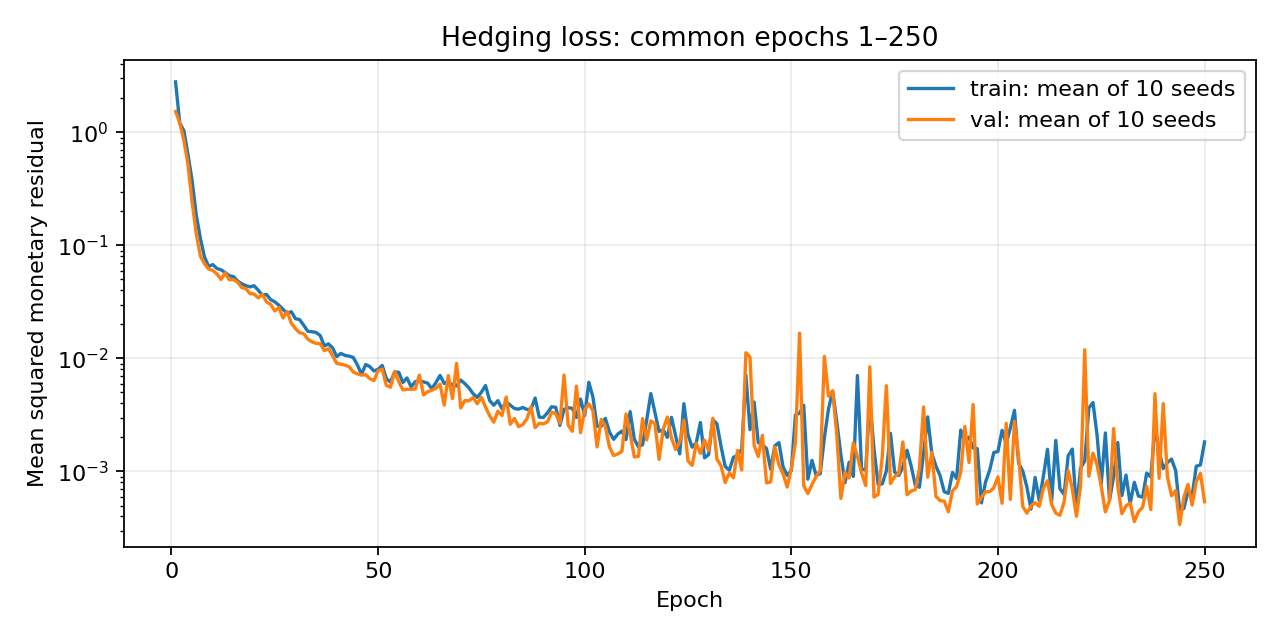

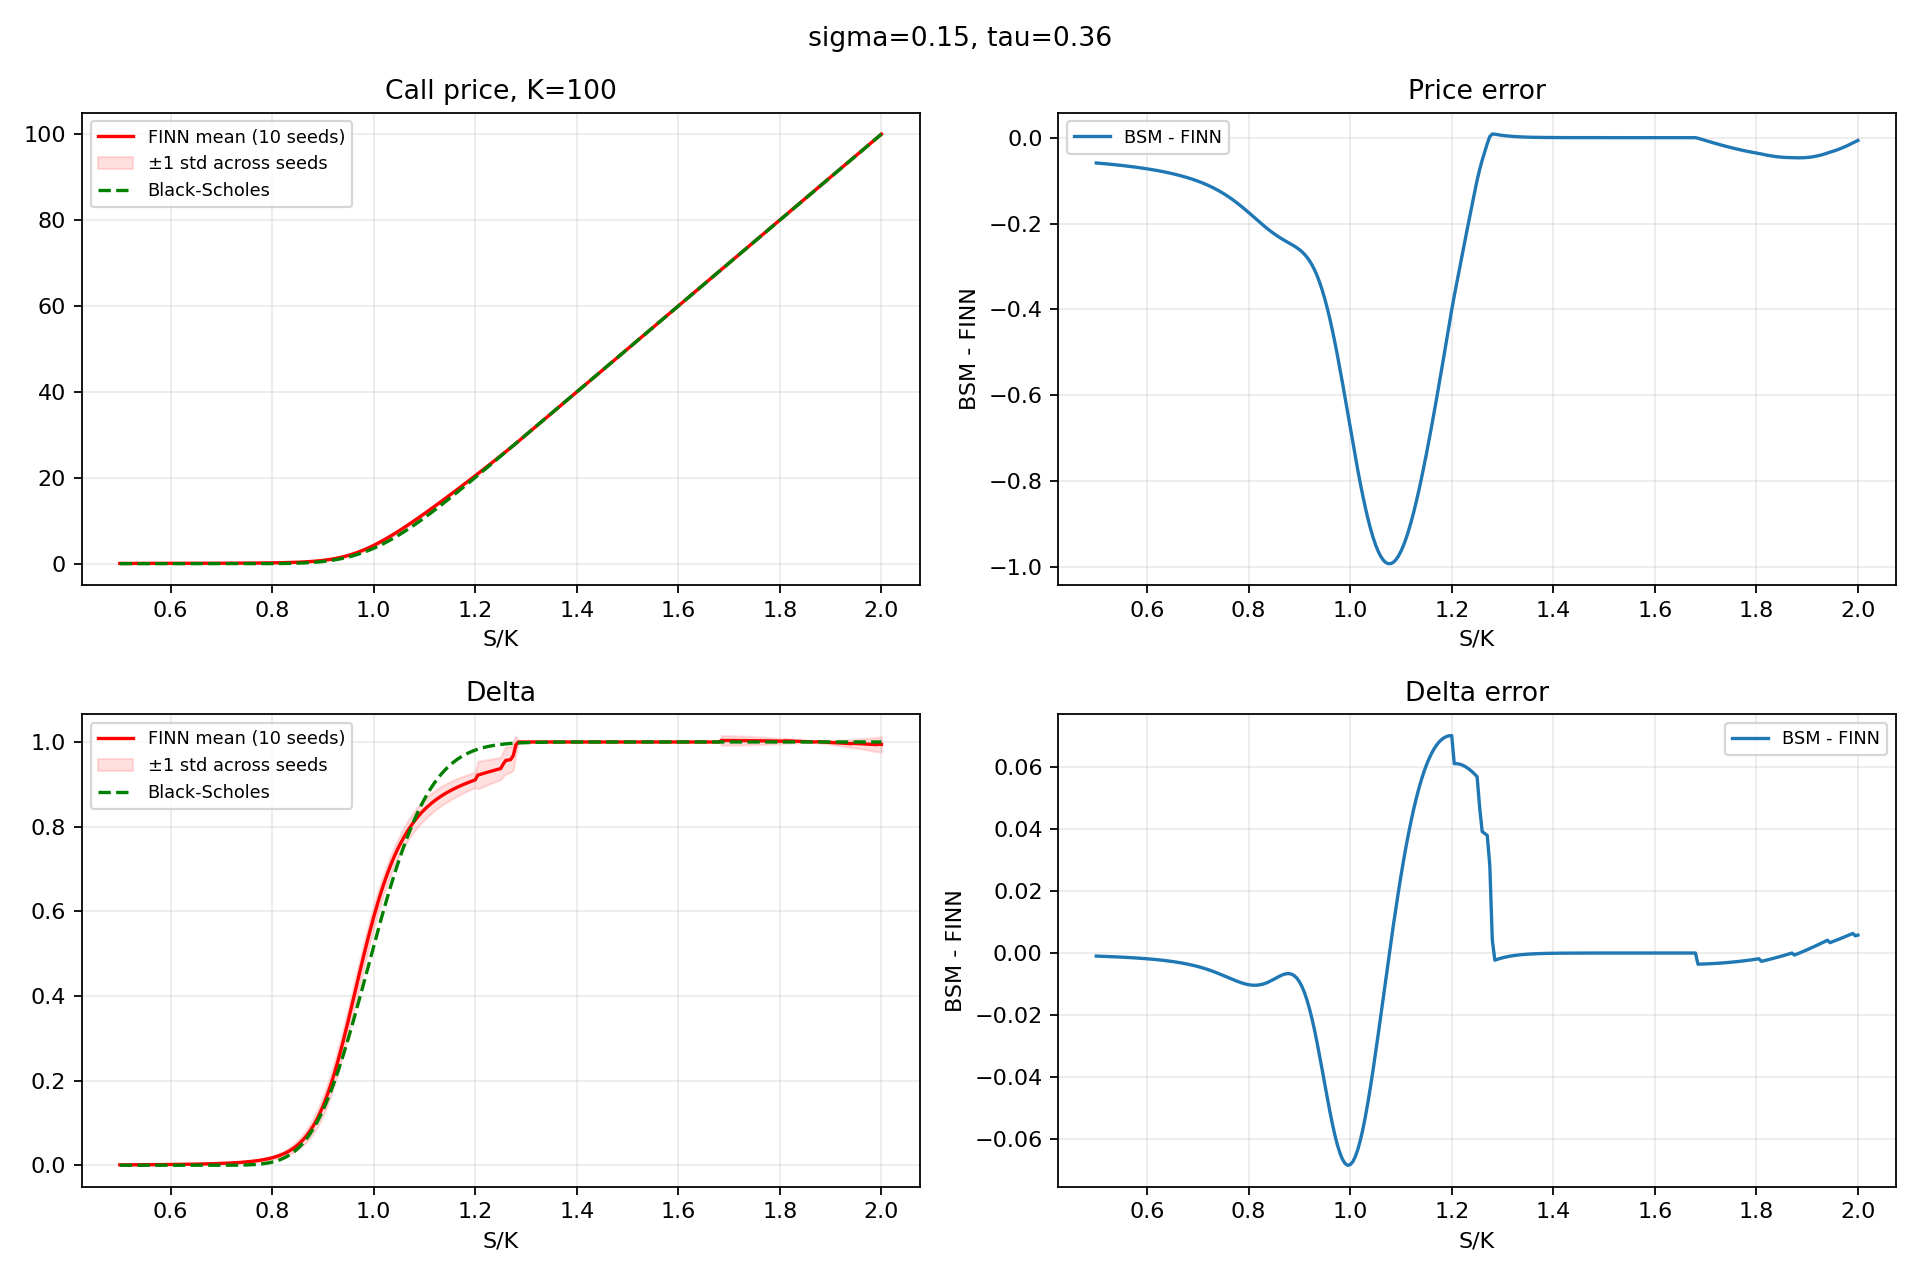

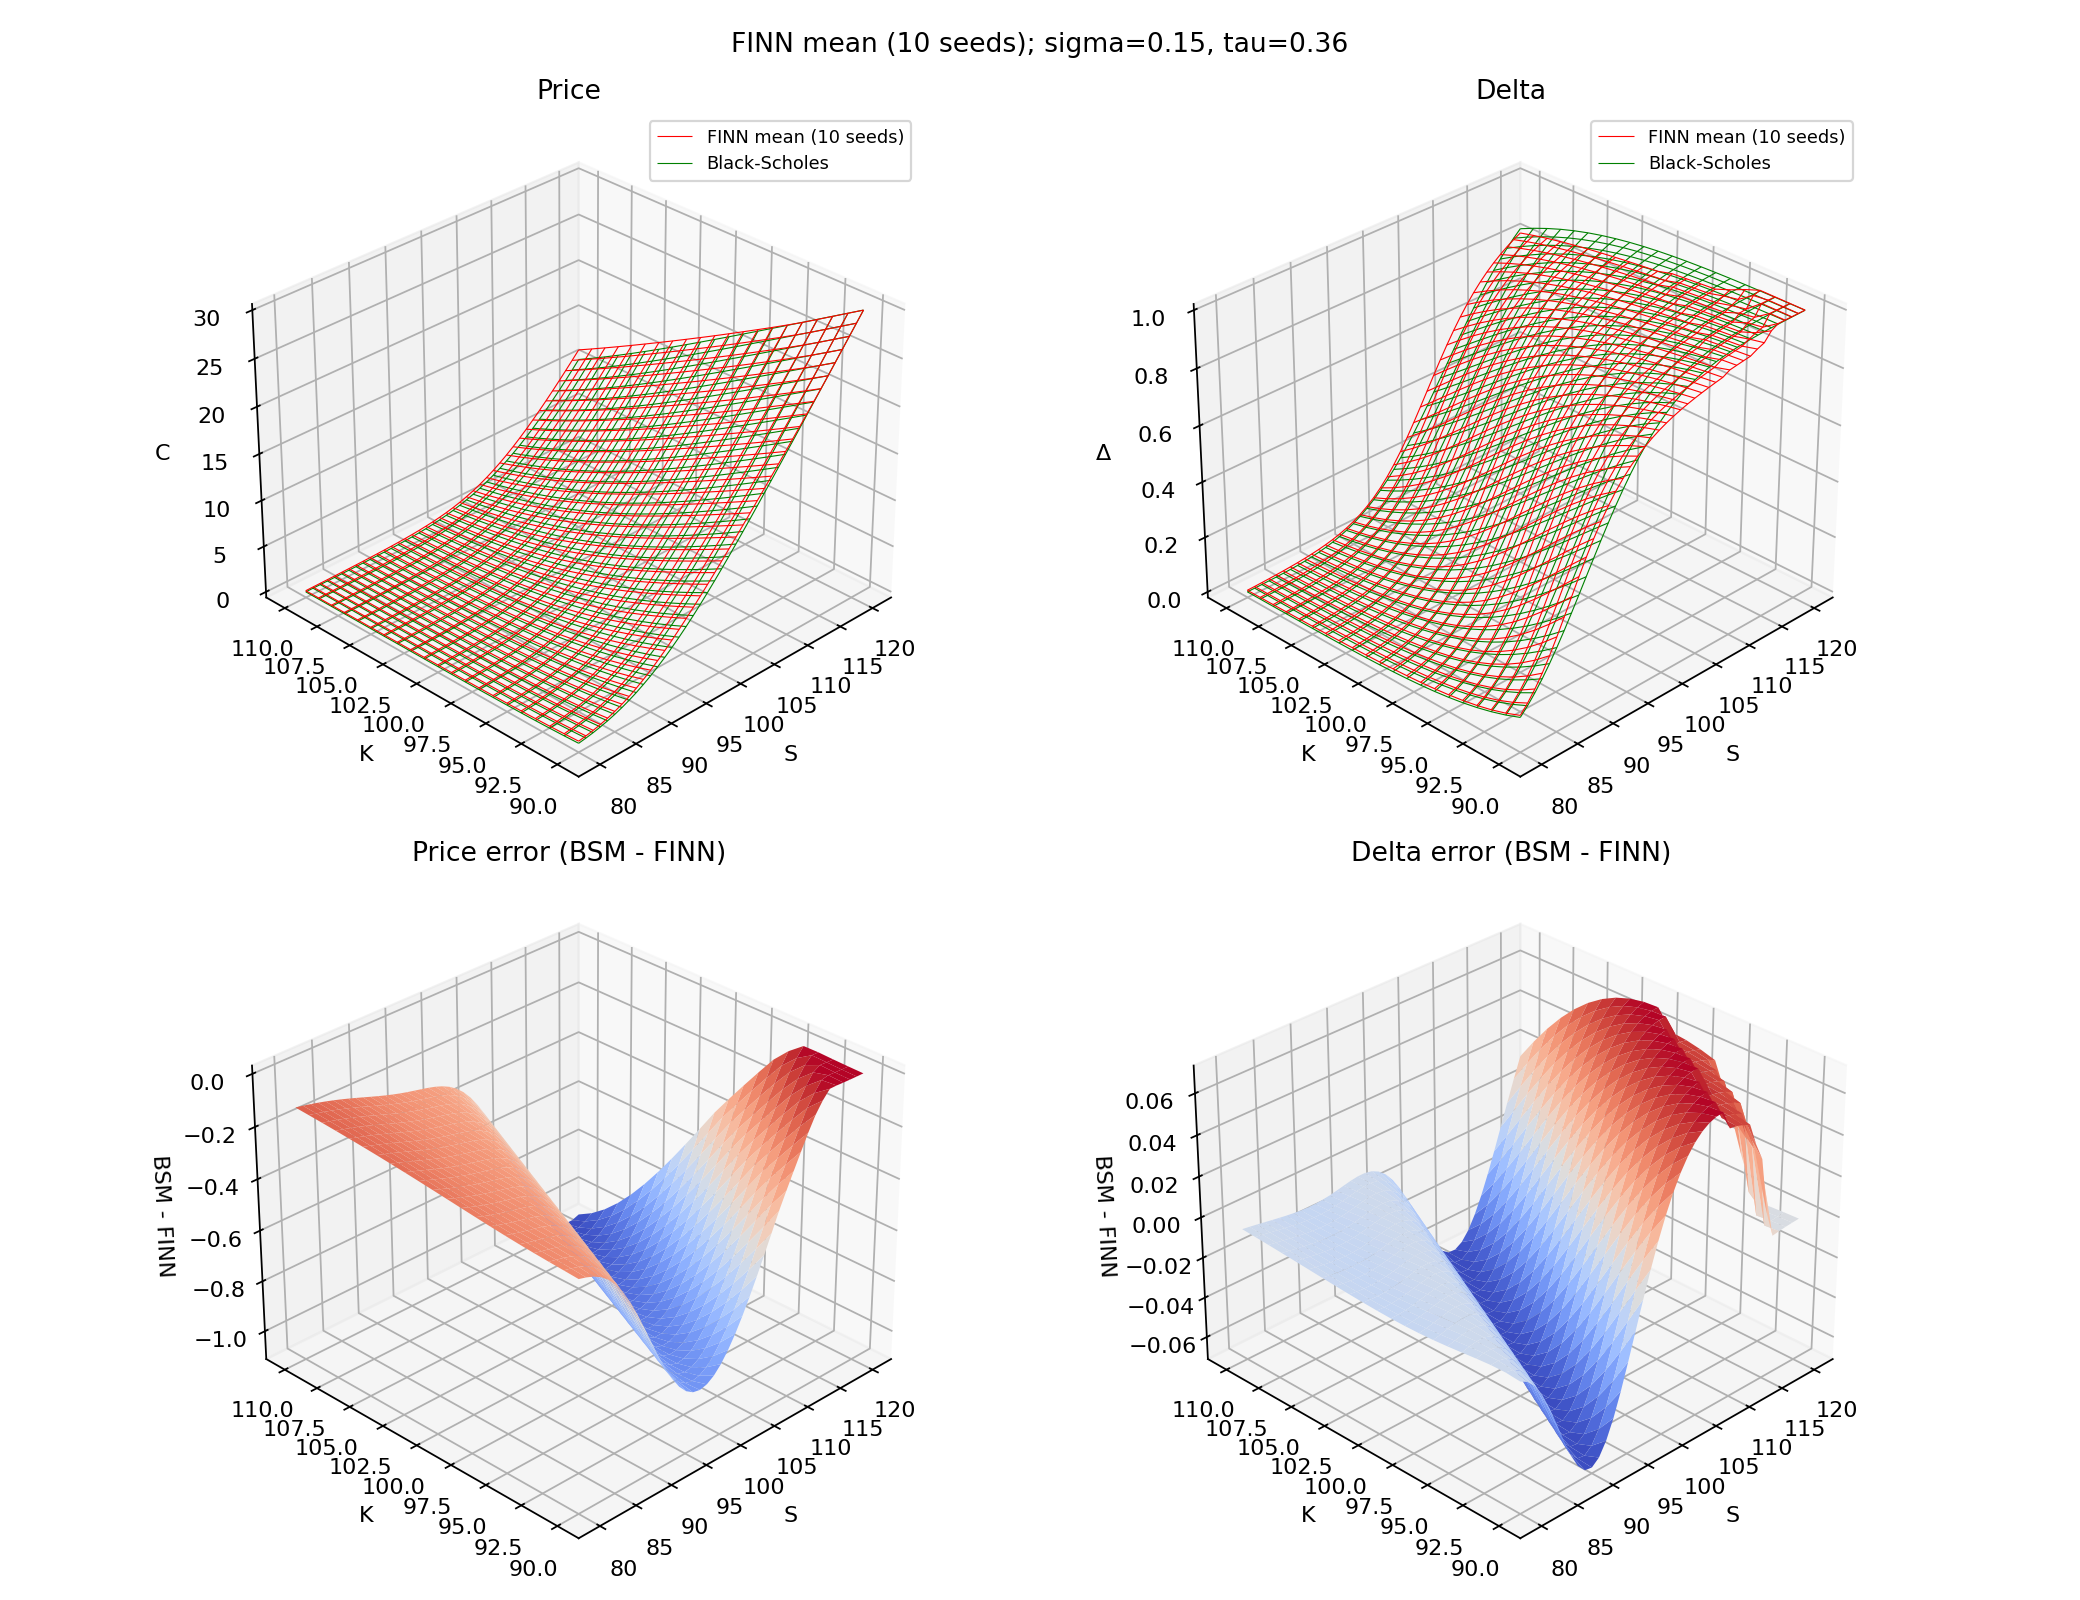

In [35]:
# Отображение средних графиков по 10 seed (методика finn_gbm_1.ipynb)

if saved is None:
    for filename in ("training_distribution.png", "training.png", "comparison.png", "surfaces.png"):
        img_path = plot_directory / filename
        if img_path.is_file():
            display(Image(filename=str(img_path)))
else:
    print("Графики checkpoint сохранены в папке оценки:", out)


## 12. Экспорт артефактов серии и оптимизация папки outputs

Единое сохранение результатов исследования и подготовка к переносу на локальный компьютер:
1. **Веса нейросетей**: веса лучших моделей `best_model.pt` для всех сидов и уровней волатильности;
2. **Неусреднённая таблица (`metrics_runs.csv`)**: подробная фиксация $\text{RMAD}$, $\text{RMSE}$, $\text{NMAD}$, $\text{MSE}$ по каждому `seed`;
3. **Сводная Таблица 9 (`table9.csv`)**: средние значения и стандартные отклонения по стандарту статьи;
4. **Результаты статистических проверок (`article_comparison.csv`)**: $p$-значения и доверительные интервалы;
5. **Очистка диска**: удаление промежуточных массивов выборок (`.npz`) и дублирующих файлов.


In [36]:
# Единое сохранение всех артефактов серии (методика finn_gbm_1.ipynb)

def cleanup_temporary_files(directory: Path, configurations: list[Config]) -> int:
    """Удаление только тяжёлых временных массивов выборок после построения всех графиков,
    сохраняя complete.json и метаданные для корректной работы completed_report."""
    cleaned = 0
    for cfg in configurations:
        fld = run_directory(directory, cfg)
        for temp_name in ("train_samples.npz", "validation_samples.npz", "last_model.pt"):
            temp_file = fld / temp_name
            if temp_file.exists():
                temp_file.unlink()
                cleaned += 1
    return cleaned

if saved is None:
    out_dir = Path(out)
    # 1. Сохранение канонической таблицы сравнения со статьёй (формат finn_gbm_1.ipynb)
    canon_rows = [
        {k: r[k] for k in ("quantity", "metric", "article", "current", "difference", "digits")}
        for r in comp_summary_rows
    ]
    write_csv(out_dir / "article_comparison.csv", canon_rows)

    # 2. Сохранение детальных результатов двухуровневого статистического теста
    stat_path = out_dir / "article_statistical_tests.csv"
    write_csv(stat_path, article_test_rows)

    # 3. Очистка тяжёлых временных файлов (.npz, last_model.pt) после построения графиков
    cleaned_count = cleanup_temporary_files(out_dir, study_configs)

    print("=" * 65)
    print("Результаты серии сохранены:")
    print(f"  - Неусреднённые метрики по сидам: {out_dir / 'metrics_runs.csv'} ({len(raw_runs)} записей)")
    print(f"  - Таблица 1 (RMAD / RMSE):        {out_dir / status['main_table']}")
    print(f"  - Таблица 9 (NMAD / MSE):         {out_dir / status['table']}")
    print(f"  - Все средние и std:              {out_dir / status['all_metrics_summary']}")
    print(f"  - Сравнение со статьёй:           {out_dir / 'article_comparison.csv'}")
    print(f"  - Статистические тесты:           {stat_path}")
    print(f"  - Веса обученных моделей:         {len(study_configs)} чекпоинтов best_model.pt")
    if cleaned_count > 0:
        print(f"  - Удалено временных файлов:       {cleaned_count} шт.")
    print("=" * 65)
    print("Перенос на Mac доступен через: ./download_vkr_results.command")


Результаты серии сохранены:
  - Неусреднённые метрики по сидам: /content/VKR/outputs/gbm_table9_699818e1e33ffcb7/metrics_runs.csv (420 записей)
  - Таблица 1 (RMAD / RMSE):        /content/VKR/outputs/gbm_table9_699818e1e33ffcb7/table1.csv
  - Таблица 9 (NMAD / MSE):         /content/VKR/outputs/gbm_table9_699818e1e33ffcb7/table9.csv
  - Все средние и std:              /content/VKR/outputs/gbm_table9_699818e1e33ffcb7/metrics_summary.csv
  - Сравнение со статьёй:           /content/VKR/outputs/gbm_table9_699818e1e33ffcb7/article_comparison.csv
  - Статистические тесты:           /content/VKR/outputs/gbm_table9_699818e1e33ffcb7/article_statistical_tests.csv
  - Веса обученных моделей:         30 чекпоинтов best_model.pt
Перенос на Mac доступен через: ./download_vkr_results.command
